# Querying FabricData

`FabricData` queries the USGS Geospatial Fabric service. It takes no key and never
receives `USGS_API_KEY`. This notebook looks up the service's collections and the
properties of `gagesii`, the GAGES-II streamgages, then collects the gages in a box
around Washington, DC, narrows the query with a CQL2 filter, and maps the result.
`to_arrow()` turns a result into a table for geopandas, which needs the `arrow` extra.

In [1]:
from water_ogcapi import FabricData

DC = (-77.12, 38.80, -76.91, 38.99)
fabric = FabricData()

A service keeps its HTTP connections open until it is closed. In a script, use it in
a `with` block, `with FabricData() as fabric:`, which closes it on exit. A notebook keeps one
service across cells, so it calls `fabric.close()` explicitly in its last cell.

## Look at the collection

`collections()` returns the index and `queryables()` the properties of one collection
that a query can name. Both are cached for an hour. Each query checks its collection
and parameter names against that cache first, so a typo raises an error that lists the
valid names.

In [2]:
ids = [collection.id for collection in fabric.collections().collections]
print(len(ids), "collections:", ", ".join(ids[:6]), "...")

31 collections: catchmentsp, nhdarea, nhdflowline_network, nhdflowline_nonnetwork, nhdwaterbody, gagesii ...


In [3]:
for name, prop in fabric.queryables("gagesii").properties.items():
    print(f"{name:12} {prop.type or prop.format}")

geometry     geometry-any
ogc_fid      integer
id           string
staid        string
staname      string
class        string
aggecoregi   string
drain_sqkm   number
huc02        string
lat_gage     number
lng_gage     number
state        string
hcdn_2009    string
active09     string
flyrs1900    integer
flyrs1950    integer
flyrs1990    integer


## Collect the gages in a box

`collect()` gathers every page into one FeatureCollection and records how the traversal
went: the checks that passed and the CRS the server named. FabricData reports
`numberMatched`, so the `count` check compares it with the features received. It sends
`X-RateLimit-*` headers on every response, which the client uses to space its requests.

In [4]:
gages = fabric.collect("gagesii", bbox=DC)
print(len(gages.geojson["features"]), "gages in", gages.pagination.page_count, "page(s)")
print(gages.pagination.completeness, gages.pagination.checks)
print(gages.crs.effective, gages.crs.source)
print("X-RateLimit-Limit:", gages.pages[0].headers["x-ratelimit-limit"])

8 gages in 1 page(s)
complete ('end_of_links', 'count', 'unique_ids')
http://www.opengis.net/def/crs/OGC/1.3/CRS84 content_crs
X-RateLimit-Limit: 300


## Filter with CQL2

A CQL2-Text `filter` combines with the bounding box. Only the gages that drain more
than 100 km²:

In [5]:
large = fabric.collect("gagesii", bbox=DC, filter="drain_sqkm > 100")
for feature in large.geojson["features"]:
    props = feature["properties"]
    print(feature["id"], props["staname"], props["drain_sqkm"])

01648000 ROCK CREEK AT SHERRILL DRIVE WASHINGTON, DC 136.8279
01649500 NORTH EAST BRANCH ANACOSTIA RIVER AT RIVERDALE, MD 188.0622
01651000 NW BRANCH ANACOSTIA RIVER NEAR HYATTSVILLE, MD 127.8054


## Read the gages with geopandas

`to_arrow()` returns a pyarrow Table whose `geometry` column carries the CRS, so
geopandas reads it as a GeoDataFrame with that CRS. Each gage is a `MultiPoint` of one
point.

In [6]:
import geopandas as gpd

frame = gpd.GeoDataFrame.from_arrow(gages.to_arrow())
print(frame.crs)
frame[["staid", "staname", "state", "drain_sqkm"]].sort_values("staid")

http://www.opengis.net/def/crs/OGC/1.3/CRS84


,staid,staname,state,drain_sqkm
0,01646550,"LITTLE FALLS BRANCH NEAR BETHESDA, MD",MD,10.5219
1,01648000,"ROCK CREEK AT SHERRILL DRIVE WASHINGTON, DC",DC,136.8279
2,01649500,NORTH EAST BRANCH ANACOSTIA RIVER AT RIVERDALE...,MD,188.0622
3,01650800,"SLIGO CREEK NEAR TAKOMA PARK, MD",MD,16.7013
4,01651000,"NW BRANCH ANACOSTIA RIVER NEAR HYATTSVILLE, MD",MD,127.8054
5,01651800,"WATTS BRANCH AT WASHINGTON, DC",DC,8.5590
6,01652500,"FOURMILE RUN AT ALEXANDRIA, VA",VA,34.5501
7,01653000,"CAMERON RUN AT ALEXANDRIA, VA",VA,87.3063


## Map the gages

The dashed rectangle is the query's bounding box. contextily draws a basemap under the
gages; its tiles are in Web Mercator (EPSG:3857), so every layer is reprojected to it.

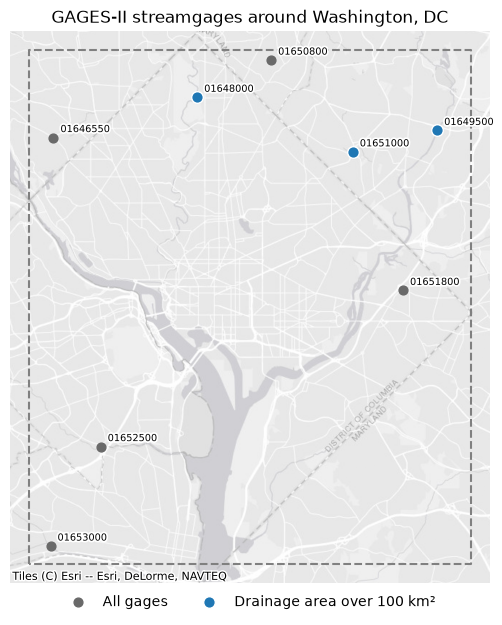

In [7]:
import contextily as ctx
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import shapely

points = frame.to_crs(3857)
big = gpd.GeoDataFrame.from_arrow(large.to_arrow()).to_crs(3857)
box = gpd.GeoSeries([shapely.box(*DC)], crs=frame.crs).to_crs(3857)
ax = points.plot(color="dimgray", markersize=40, figsize=(6, 6.5), label="All gages")
big.plot(
    ax=ax,
    color="tab:blue",
    edgecolor="white",
    markersize=70,
    label="Drainage area over 100 km²",
)
halo = [pe.withStroke(linewidth=2.5, foreground="white")]
for row in points.itertuples():
    x, y = row.geometry.centroid.coords[0]
    ax.annotate(
        row.staid, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=7, path_effects=halo
    )
box.boundary.plot(ax=ax, color="gray", linestyle="--")
west, south, east, north = box.total_bounds
ax.set_xlim(west - 1000, east + 1000)  # meters
ax.set_ylim(south - 1000, north + 1000)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncols=2, frameon=False)
ax.set(title="GAGES-II streamgages around Washington, DC")
ax.set_axis_off()
plt.tight_layout()

In [8]:
fabric.close()